In [1]:
%gui asyncio

In [2]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

import tifffile
from tqdm import tqdm
import pygpcca

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [3]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [4]:
movie_raw = tifffile.imread("/home/kushal/lab/datasets/vaz/vaz_rect-2_z-0_mcorr.tif")

In [5]:
movie_raw.shape

(1730, 592, 140)

In [6]:
%matplotlib inline

In [7]:
iw_movie = fpl.ImageWidget(movie_raw, cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
iw_movie.show()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


WGPU: map() is deprecated, use map_sync() instead.


In [9]:
iw_movie.window_funcs = {"t": (np.mean, 7)}

In [28]:
iw = fpl.ImageWidget(movie_raw - np.min(movie_raw, axis=0), cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
rs = iw.managed_graphics[0].add_rectangle_selector()
iw.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [ ]:
tuple(rs.selection.astype(int).tolist())

In [8]:
rect1 = (0, 140, 0, 144)
rect2 = (0, 140, 141, 285)
rect3 = (0, 140, 287, 431)
rect4 = (0, 140, 449, 592)

In [9]:
import numba

@numba.guvectorize([(numba.float32[:], numba.float32[:])], "(n)->(n)")
def rolling_percentile(trace: np.ndarray, out: np.ndarray):
    for i in range(0, trace.size - 1):
        out[i] = np.percentile(trace[i:i + 30], 5)


@numba.njit(parallel=True)
def rolling_percentile_movie(m, output):
    t, row, col = m.shape
    for i in numba.prange(row):
        for j in range(col):
            rolling_percentile(m[:, i, j], output[:, i, j])

In [10]:
rows = slice(*rect1[2:], 2)
cols = slice(*rect1[:2], 2)

sub_raw = movie_raw[:, rows, cols].astype(np.float32)[..., 5:-5].copy()
sub_raw -= sub_raw.min(axis=0)
sub = sub_raw
# sub = np.zeros(sub_raw.shape, dtype=np.float32)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
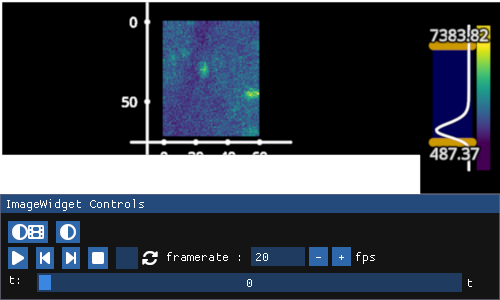

In [11]:
fpl.ImageWidget(sub, cmap="viridis").show()

In [107]:
sub = sub[:-10]

In [ ]:
fpl.ImageWidget([sub, sub.std(axis=0), sub.mean(axis=0)], cmap="gnuplot2").show()

In [200]:
Y = sub.reshape(sub.shape[0], sub.shape[1] * sub.shape[2]).T.astype(np.float64)
Y.shape

(4320, 1730)

In [109]:
from scipy.ndimage import gaussian_filter1d

In [146]:
gfiltered = gaussian_filter1d(Y, sigma=8, axis=1, order=1)
# Yd = np.abs(np.gradient(gfiltered, axis=1))
Yg = gfiltered

In [143]:
filt_movie = Yg.T.reshape(Yg.shape[1], *sub.shape[1:])
# filt_movie -= filt_movie.min(axis=0)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
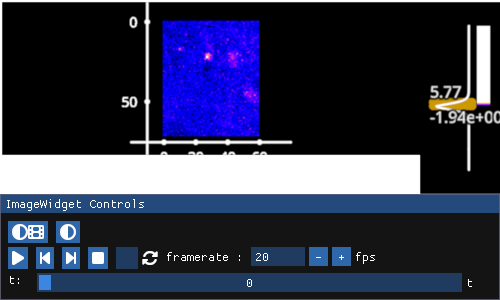

In [115]:
fpl.ImageWidget(filt_movie, cmap="gnuplot2").show()

In [201]:
from sklearn.metrics import pairwise_distances

In [202]:
B = pairwise_distances(Y, Y, n_jobs=20, metric="correlation")

RFBOutputContext()

JupyterWgpuCanvas()
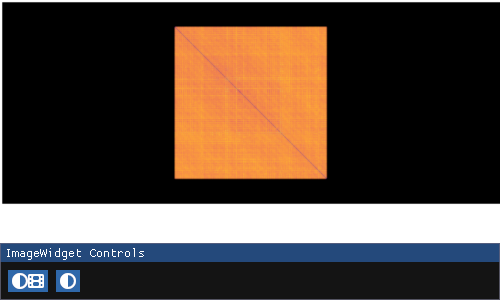

In [203]:
fpl.ImageWidget(B, histogram_widget=False).show()

In [204]:
B.min(), B.max()

(np.float64(0.0), np.float64(1.2892229674481739))

In [205]:
d = 1.0 / np.sum(B.astype(np.float64), axis=1)

In [206]:
A = np.diag(d) @ B

In [207]:
A.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

RFBOutputContext()

JupyterWgpuCanvas()
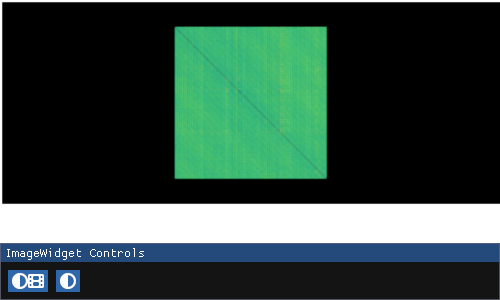

In [208]:
iw_s = fpl.ImageWidget(A, cmap="viridis", histogram_widget=False)
iw_s.show()

In [209]:
A.min(), A.max()

(np.float64(0.0), np.float64(0.00034870408316080764))

In [210]:
np.sum(A[0, :])

np.float64(0.9999999999999978)

In [211]:
A.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

In [212]:
import pygpcca as gp

In [213]:
gpcca = gp.GPCCA(A, z="LM", method="brandts")

In [214]:
mc = gpcca.minChi(18, 25)

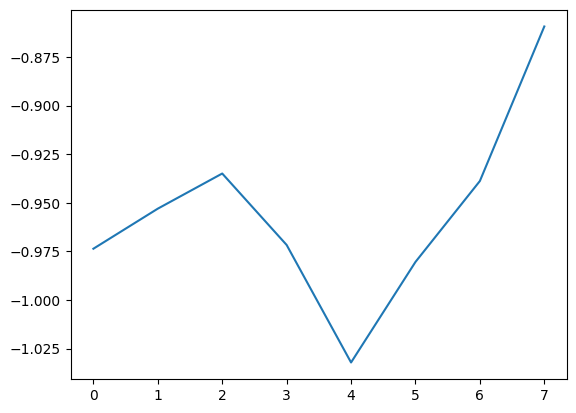

In [215]:
plt.plot(mc)

In [216]:
mc

[np.float64(-0.9736226214825595),
 np.float64(-0.9530185760204385),
 np.float64(-0.9349522624945843),
 np.float64(-0.971688306848088),
 np.float64(-1.0321219568960929),
 np.float64(-0.9804153817338842),
 np.float64(-0.9387965742986026),
 np.float64(-0.8593383874656972)]

In [217]:
np.argmax(mc)

np.int64(7)

In [218]:
%%time
gpcca.optimize(25)

CPU times: user 1min 25s, sys: 81.6 ms, total: 1min 25s
Wall time: 1min 25s


GPCCA[n=4320, n_macrostates=25]

In [219]:
gpcca.memberships.shape

(4320, 25)

In [220]:
gpcca.crispness_values

array([0.04582076])

In [221]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [222]:
from ipywidgets import HBox

In [223]:
from fastplotlib.ui import EdgeWindow
from imgui_bundle import imgui

In [224]:
fig_comps = fpl.Figure(canvas="glfw")

ix = 0
for i in range(7):
    for j in range(4):
        if ix > labels.shape[-1] - 1:
            break
        img = labels.T[ix].T
        fig_comps[0, 0].add_image(img, cmap="viridis", offset=(i * img.shape[1] + 10 * i, j * img.shape[0] + 10 * j, 0))
        ix += 1

fig_comps.show()#, iw_movie.show()

In [337]:
iw_movie.window_funcs = {"t": (np.mean, 5)}

In [338]:
for i, _ in enumerate(labels.T):
    iw.managed_graphics[i].vmin = np.percentile(labels.T[i], 90)
    iw.managed_graphics[i].vmax = labels.T[i].max()

IndexError: list index out of range

In [ ]:
from ipywidgets import VBox

In [ ]:
iw1 = fpl.ImageWidget(sub)
iw2 = fpl.ImageWidget(sub)

fig = fpl.Figure()

fig[0, 0].add_scatter(np.argwhere(labels.T[3] > 0.1), colors="g", sizes=10, alpha=0.4)
fig[0, 0].add_scatter(np.argwhere(labels.T[8] > 0.15), colors="r", sizes=10, alpha=0.4)

VBox([fig.show(), HBox([iw1.show(), iw2.show()])])

In [42]:
fig.renderer.blend_mode = "weighted_plus"

In [43]:
iw1.current_index = {"t": 2288}
iw2.current_index = {"t": 3972}

In [44]:
gpcca.coarse_grained_transition_matrix.min()

np.float64(0.020271349682074485)

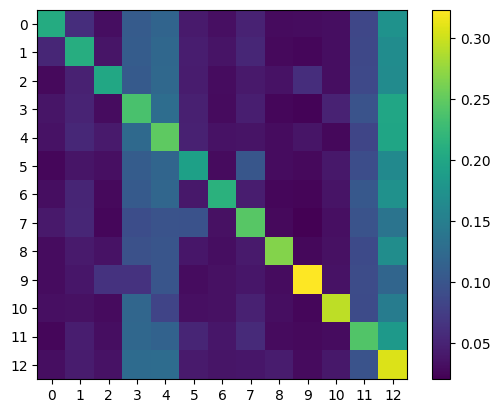

array([[0.20637425, 0.06001968, 0.03165649, 0.10761106, 0.11825953,
        0.04267813, 0.03252963, 0.049109  , 0.02971941, 0.03059786,
        0.03168177, 0.08495982, 0.17480337],
       [0.05240353, 0.20922359, 0.03782766, 0.10794889, 0.12097869,
        0.04418016, 0.03613014, 0.05282541, 0.02764983, 0.02597006,
        0.03198886, 0.08557976, 0.16729342],
       [0.02743826, 0.04856128, 0.20234833, 0.10591334, 0.12221456,
        0.04326885, 0.02993824, 0.04068926, 0.03529704, 0.05938069,
        0.03192726, 0.08707221, 0.16595067],
       [0.03696616, 0.05043668, 0.0297486 , 0.23677653, 0.12841798,
        0.04718043, 0.02904891, 0.04581267, 0.02570839, 0.02290876,
        0.04913828, 0.09801692, 0.19983969],
       [0.03528057, 0.05413678, 0.04159435, 0.12364881, 0.24827496,
        0.04760441, 0.03541237, 0.03676327, 0.03012524, 0.03776509,
        0.02658075, 0.08415478, 0.19865862],
       [0.02595015, 0.03712791, 0.03272326, 0.10847392, 0.11867696,
        0.19247629, 0.02952

In [45]:
P_c = gpcca.coarse_grained_transition_matrix
# plot P_c:
fig, ax = plt.subplots()
c = ax.imshow(P_c)
plt.xticks(np.arange(P_c.shape[1]))
plt.yticks(np.arange(P_c.shape[0]))
plt.ylim(-0.5, P_c.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show P_c matrix:
P_c

In [51]:
gpcca.coarse_grained_transition_matrix[gpcca.coarse_grained_transition_matrix < 0]

array([], dtype=float64)

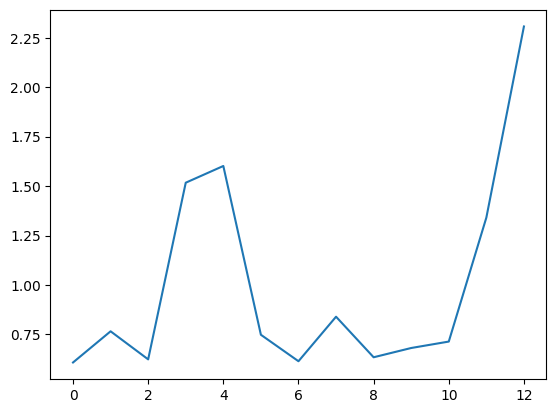

In [52]:
plt.plot(gpcca.coarse_grained_transition_matrix.sum(axis=0))